# Proyek Analisis Data: Air Quality Dataset 
- **Nama:** Melvan Safero Lee
- **Email:** melvansafero@gmail.com
- **ID Dicoding:** melvanslee2505

## Menentukan Pertanyaan Bisnis

***“Faktor polutan dan kondisi meteorologi apa saja yang berhubungan dengan peningkatan konsentrasi PM2.5 di stasiun pemantauan di kota Beijing, selama periode Maret 2013 hingga Februari 2017, dan bagaimana hasil analisis dapat digunakan untuk menentukan prioritas pemantauan kualitas udara?”"***

Keterangan:

- **Specific**: Berfokus pada peningkatan konsentrasi PM2.5 di stasiun Changping, Beijing, berdasarkan variabel polutan dan meteorologi.
- **Measurable**: Menggunakan rata-rata konsentrasi PM2.5, korelasi antarvariabel, serta perbandingan konsentrasi berdasarkan waktu dan kondisi cuaca.
- **Action-Oriented**: Hasil analisis dapat membantu mengidentifikasi periode dengan konsentrasi PM2.5 tinggi dan menentukan prioritas pemantauan kualitas udara.
- **Relevant**: Analisis mendukung pemantauan pencemaran udara dan pengambilan keputusan terkait kualitas lingkungan.
- **Time-bound**: Analisis dibatasi pada periode Maret 2013 hingga Februari 2017.

- **Pertanyaan 1:** Bagaimana perubahan rata-rata konsentrasi PM2.5 per jam dan per bulan selama periode Maret 2013 hingga Februari 2017?
- **Pertanyaan 2:** Seberapa kuat hubungan antara konsentrasi PM2.5 dan variabel meteorologi, seperti suhu, tekanan udara, curah hujan, kelembapan titik embun, serta kecepatan angin?
- **Pertanyaan 3:** Polutan apa yang memiliki hubungan paling kuat dengan konsentrasi PM2.5?
- **Pertanyaan 4:** Pada bulan dan jam berapa konsentrasi PM2.5 paling sering mencapai tingkat tinggi?
- **Pertanyaan 5:** Bagaimana perbedaan rata-rata konsentrasi PM2.5 antara musim dingin, semi, panas, dan gugur?
- **Pertanyaan 6:** Variabel apa yang paling informatif untuk memprediksi konsentrasi PM2.5 dan membantu menentukan prioritas pemantauan kualitas udara?

## Import Semua Packages/Library yang Digunakan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load DataFrame

In [3]:
file_path = Path("/Users/melvankerja/Desktop/VSCode/Proyek_Analisis/PRSA_Data_Changping_20130301-20170228.csv")
df = pd.read_csv(file_path)
print("Ukuran dataset:", df.shape)
display(df.head())
display(df.info())

Ukuran dataset: (35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,3.00,6.00,13.00,7.00,300.00,85.00,-2.30,1020.80,-19.70,0.00,E,0.50,Changping
1,2,2013,3,1,1,3.00,3.00,6.00,6.00,300.00,85.00,-2.50,1021.30,-19.00,0.00,ENE,0.70,Changping
2,3,2013,3,1,2,3.00,3.00,22.00,13.00,400.00,74.00,-3.00,1021.30,-19.90,0.00,ENE,0.20,Changping
3,4,2013,3,1,3,3.00,6.00,12.00,8.00,300.00,81.00,-3.60,1021.80,-19.10,0.00,NNE,1.00,Changping
4,5,2013,3,1,4,3.00,3.00,14.00,8.00,300.00,81.00,-3.50,1022.30,-19.40,0.00,N,2.10,Changping


<class 'pandas.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34290 non-null  float64
 6   PM10     34482 non-null  float64
 7   SO2      34436 non-null  float64
 8   NO2      34397 non-null  float64
 9   CO       33543 non-null  float64
 10  O3       34460 non-null  float64
 11  TEMP     35011 non-null  float64
 12  PRES     35014 non-null  float64
 13  DEWP     35011 non-null  float64
 14  RAIN     35013 non-null  float64
 15  wd       34924 non-null  str    
 16  WSPM     35021 non-null  float64
 17  station  35064 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 5.2 MB


None

**Insight:** 
- Dataset PRSA Data Changping memiliki 35.064 baris dan 18 kolom, yang mencakup informasi waktu, konsentrasi polutan udara, kondisi meteorologi, dan identitas stasiun pemantauan.

- Dataset mencatat pengamatan per jam dari Maret 2013 hingga Februari 2017. Kolom year, month, day, dan hour dapat digunakan untuk membentuk variabel waktu (datetime) agar analisis tren temporal dapat dilakukan.

- Dataset memiliki 11 kolom numerik bertipe float64, 5 kolom bertipe int64, dan 2 kolom bertipe string (wd dan station).

- Variabel PM2.5 dipilih sebagai fokus utama analisis karena merepresentasikan konsentrasi partikel halus di udara. Variabel polutan lainnya dan kondisi meteorologi dapat digunakan untuk mengeksplorasi pola yang berhubungan dengan perubahan konsentrasi PM2.5.

- Berdasarkan jumlah nilai non-null, beberapa kolom memiliki missing values, terutama CO (33.543 nilai valid), NO2 (34.397), dan SO2 (34.436). Oleh karena itu, diperlukan pemeriksaan kualitas data lebih lanjut sebelum melakukan analisis.

### Assessing Data - Identifying Problems

In [4]:
# 1. Struktur dataset
print("Jumlah baris dan kolom:", df.shape)
print("\nTipe data:")
print(df.dtypes)

# 2. Missing values
missing = df.isna().sum()
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percentage": (missing / len(df) * 100).round(2)
})
display(missing_summary[missing_summary["missing_count"] > 0])

# 3. Duplikasi
print("Jumlah baris duplikat:", df.duplicated().sum())

# 4. Duplikasi observasi berdasarkan waktu
print(
    "Duplikasi kombinasi waktu:",
    df.duplicated(subset=["year", "month", "day", "hour"]).sum()
)

# 5. Statistik deskriptif
display(df.describe(include="all").T)

# 6. Pemeriksaan nilai negatif pada variabel yang tidak boleh negatif
nonnegative_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "RAIN", "WSPM"
]

for col in nonnegative_cols:
    if col in df.columns:
        print(f"{col}: {(df[col] < 0).sum()} nilai negatif")

Jumlah baris dan kolom: (35064, 18)

Tipe data:
No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd             str
WSPM       float64
station        str
dtype: object


,missing_count,missing_percentage
PM2.5,774,2.21
PM10,582,1.66
SO2,628,1.79
NO2,667,1.90
CO,1521,4.34
O3,604,1.72
TEMP,53,0.15
PRES,50,0.14
DEWP,53,0.15
RAIN,51,0.15


Jumlah baris duplikat: 0
Duplikasi kombinasi waktu: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
No,35064.00,NaN,NaN,NaN,17532.50,10122.25,1.00,8766.75,17532.50,26298.25,35064.00
year,35064.00,NaN,NaN,NaN,2014.66,1.18,2013.00,2014.00,2015.00,2016.00,2017.00
month,35064.00,NaN,NaN,NaN,6.52,3.45,1.00,4.00,7.00,10.00,12.00
day,35064.00,NaN,NaN,NaN,15.73,8.80,1.00,8.00,16.00,23.00,31.00
hour,35064.00,NaN,NaN,NaN,11.50,6.92,0.00,5.75,11.50,17.25,23.00
PM2.5,34290.00,NaN,NaN,NaN,71.10,72.33,2.00,18.00,46.00,100.00,882.00
PM10,34482.00,NaN,NaN,NaN,94.66,83.44,2.00,34.00,72.00,131.00,999.00
SO2,34436.00,NaN,NaN,NaN,14.96,20.98,0.29,2.00,7.00,18.00,310.00
NO2,34397.00,NaN,NaN,NaN,44.18,29.52,1.85,22.00,36.00,60.36,226.00
CO,33543.00,NaN,NaN,NaN,1152.30,1103.06,100.00,500.00,800.00,1400.00,10000.00


PM2.5: 0 nilai negatif
PM10: 0 nilai negatif
SO2: 0 nilai negatif
NO2: 0 nilai negatif
CO: 0 nilai negatif
O3: 0 nilai negatif
RAIN: 0 nilai negatif
WSPM: 0 nilai negatif


**Insight:** 
- Problem 1 — Missing Values: Dataset memiliki nilai kosong pada sejumlah variabel. Kolom CO memiliki missing values terbanyak, yaitu 1.521 (4,34%), diikuti PM2.5 sebanyak 774 (2,21%), NO2 sebanyak 667 (1,90%), SO2 sebanyak 628 (1,79%), dan PM10 sebanyak 582 (1,66%). Missing values perlu ditangani agar tidak mengurangi kualitas analisis kualitas udara.

- Problem 2 — Outliers: Statistik deskriptif menunjukkan nilai maksimum yang jauh lebih tinggi daripada kuartil ketiga pada beberapa variabel, misalnya PM2.5 sebesar 882 dibandingkan Q3 sebesar 100, PM10 sebesar 999 dibandingkan Q3 sebesar 131, dan CO sebesar 10.000 dibandingkan Q3 sebesar 1.400. Kondisi ini mengindikasikan adanya nilai ekstrem yang perlu diperiksa lebih lanjut untuk membedakan lonjakan polusi yang valid dari kesalahan pencatatan.

- Hasil pemeriksaan tambahan: Tidak ditemukan baris duplikat maupun duplikasi kombinasi waktu berdasarkan output yang ditampilkan. Selain itu, tidak ditemukan nilai negatif pada variabel polutan, curah hujan, dan kecepatan angin yang diperiksa.

- Kesimpulan: Permasalahan utama yang perlu diprioritaskan pada tahap cleaning adalah penanganan missing values dan pemeriksaan outliers. Data ekstrem tidak boleh langsung dihapus karena dapat merepresentasikan kejadian pencemaran udara yang nyata.

**Steps to Take — Cleaning Data**
1. Menangani missing values dengan mempertimbangkan karakteristik setiap variabel dan urutan waktu. Interpolasi temporal dapat dipertimbangkan untuk celah pendek, sedangkan celah panjang perlu dievaluasi secara terpisah.
2. Memeriksa outliers menggunakan metode IQR dan boxplot, kemudian memvalidasi nilai ekstrem sebelum memutuskan apakah perlu dikoreksi atau dipertahankan.
3. Memeriksa kembali jumlah missing values, duplikasi, dan statistik deskriptif setelah cleaning untuk memastikan kualitas data meningkat.

### Cleaning Data - Fixing Problem

In [5]:
df_clean = df.copy()

# Hapus baris yang identik sepenuhnya
df_clean = df_clean.drop_duplicates()

# Buat timestamp
df_clean["datetime"] = pd.to_datetime(
    df_clean[["year", "month", "day", "hour"]],
    errors="coerce"
)

# Hapus timestamp yang tidak valid
df_clean = df_clean.dropna(subset=["datetime"])

# Urutkan berdasarkan waktu
df_clean = df_clean.sort_values("datetime")

# Periksa timestamp duplikat
duplicate_time = df_clean["datetime"].duplicated().sum()
print("Timestamp duplikat setelah pembersihan:", duplicate_time)

# Karena dataset ini untuk satu stasiun, periksa sebelum menghapus
# observasi dengan timestamp yang sama.
if duplicate_time > 0:
    print("Perlu investigasi timestamp duplikat sebelum menentukan tindakan.")

# Interpolasi hanya untuk missing values numerik yang berada
# di antara dua pengamatan valid; jangan mengisi semua kolom secara buta.
numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()

df_clean = df_clean.set_index("datetime")

df_clean[numeric_cols] = df_clean[numeric_cols].interpolate(
    method="time",
    limit=3,
    limit_area="inside"
)

df_clean = df_clean.reset_index()

print("Ukuran sebelum cleaning:", df.shape)
print("Ukuran setelah cleaning:", df_clean.shape)
print("Sisa missing values:", df_clean.isna().sum().sum())

display(df_clean.head())

Timestamp duplikat setelah pembersihan: 0
Ukuran sebelum cleaning: (35064, 18)
Ukuran setelah cleaning: (35064, 19)
Sisa missing values: 2590


,datetime,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,2013-03-01 00:00:00,1,2013,3,1,0,3.00,6.00,13.00,7.00,300.00,85.00,-2.30,1020.80,-19.70,0.00,E,0.50,Changping
1,2013-03-01 01:00:00,2,2013,3,1,1,3.00,3.00,6.00,6.00,300.00,85.00,-2.50,1021.30,-19.00,0.00,ENE,0.70,Changping
2,2013-03-01 02:00:00,3,2013,3,1,2,3.00,3.00,22.00,13.00,400.00,74.00,-3.00,1021.30,-19.90,0.00,ENE,0.20,Changping
3,2013-03-01 03:00:00,4,2013,3,1,3,3.00,6.00,12.00,8.00,300.00,81.00,-3.60,1021.80,-19.10,0.00,NNE,1.00,Changping
4,2013-03-01 04:00:00,5,2013,3,1,4,3.00,3.00,14.00,8.00,300.00,81.00,-3.50,1022.30,-19.40,0.00,N,2.10,Changping


**Insight:** 
- Timestamp berhasil dibuat: Kolom datetime berhasil menggabungkan informasi year, month, day, dan hour. Dataset sekarang memiliki 19 kolom, bertambah satu kolom dari dataset awal.

- Tidak ada timestamp duplikat: Hasil pemeriksaan menunjukkan 0 timestamp duplikat, sehingga tidak diperlukan penghapusan observasi berdasarkan duplikasi waktu.

- Jumlah observasi dipertahankan: Dataset tetap memiliki 35.064 baris setelah proses cleaning. Tidak ada baris yang hilang akibat proses tersebut.

- Missing values masih tersisa: Terdapat 2.590 nilai kosong setelah interpolasi. Hal ini menunjukkan bahwa sebagian missing values belum dapat ditangani, sehingga perlu diperiksa kembali berdasarkan variabel dan pola waktu.

- Kesimpulan: Struktur waktu dataset sudah siap untuk analisis temporal, tetapi penanganan missing values perlu dievaluasi sebelum hasil EDA diinterpretasikan.

## Exploratory Data Analysis (EDA)

### EDA 1 - Statistik deskriptif dan tren waktu

In [6]:
print("Statistik PM2.5:")
display(df_clean["PM2.5"].describe())

monthly_pm25 = (
    df_clean.set_index("datetime")["PM2.5"]
    .resample("MS")
    .mean()
)

print("Bulan dengan rata-rata PM2.5 tertinggi:")
display(monthly_pm25.nlargest(5))

print("Bulan dengan rata-rata PM2.5 terendah:")
display(monthly_pm25.nsmallest(5))

Statistik PM2.5:


count   34632.00
mean       71.15
std        72.48
min         2.00
25%        18.00
50%        46.00
75%       100.00
max       882.00
Name: PM2.5, dtype: float64

Bulan dengan rata-rata PM2.5 tertinggi:


datetime
2014-02-01   140.81
2015-12-01   120.31
2014-10-01   117.34
2016-12-01   109.82
2014-04-01   104.50
Name: PM2.5, dtype: float64

Bulan dengan rata-rata PM2.5 terendah:


datetime
2016-08-01   36.67
2016-02-01   38.42
2015-08-01   38.53
2015-09-01   43.03
2016-09-01   44.80
Name: PM2.5, dtype: float64

**Insight:** 
- Rata-rata konsentrasi PM2.5: Konsentrasi PM2.5 memiliki rata-rata sebesar 71,15, median 46, nilai minimum 2, dan maksimum 882. Rata-rata yang lebih tinggi daripada median menunjukkan distribusi yang cenderung menceng ke kanan (right-skewed), dengan sejumlah observasi berkonsentrasi tinggi.

- Bulan dengan rata-rata PM2.5 tertinggi: Februari 2014, dengan rata-rata 140,81, diikuti Desember 2015 sebesar 120,31 dan Oktober 2014 sebesar 117,34.

- Bulan dengan rata-rata PM2.5 terendah: Agustus 2016, dengan rata-rata 36,67, diikuti Februari 2016 sebesar 38,42 dan Agustus 2015 sebesar 38,53.

- Pola temporal: Hasil tersebut menunjukkan variasi konsentrasi PM2.5 antarbulan. Bulan-bulan dengan rata-rata tinggi dan rendah dapat digunakan sebagai dasar untuk mengeksplorasi pola musiman, tetapi belum cukup untuk menyimpulkan tren jangka panjang atau penyebab perubahan polusi.

### EDA 2 - Hubungan antarvariabel

In [7]:
pollution_weather_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

corr = df_clean[pollution_weather_cols].corr(
    method="spearman",
    numeric_only=True
)

display(corr["PM2.5"].sort_values(ascending=False))

PM2.5    1.00
PM10     0.88
CO       0.82
NO2      0.64
SO2      0.43
DEWP     0.22
RAIN    -0.00
TEMP    -0.04
PRES    -0.06
O3      -0.22
WSPM    -0.33
Name: PM2.5, dtype: float64

**Insight:** 
- Hubungan positif terkuat: PM10 memiliki korelasi Spearman sebesar 0,88 dengan PM2.5, diikuti CO sebesar 0,82 dan NO2 sebesar 0,64. Hal ini menunjukkan bahwa konsentrasi PM2.5 cenderung meningkat ketika nilai variabel tersebut meningkat.

- Hubungan positif sedang: SO2 memiliki korelasi 0,43, sedangkan DEWP memiliki korelasi 0,22 dengan PM2.5.

- Hubungan negatif: Kecepatan angin (WSPM) memiliki korelasi negatif sebesar −0,33, diikuti O3 sebesar −0,22. Suhu (TEMP) dan tekanan udara (PRES) memiliki korelasi negatif yang relatif lemah, masing-masing −0,04 dan −0,06.

- Hubungan yang sangat lemah: Curah hujan (RAIN) memiliki korelasi yang mendekati nol pada hasil yang ditampilkan.

- Implikasi analisis: PM10, CO, dan NO2 merupakan variabel yang paling kuat berhubungan secara monotonik dengan PM2.5 dalam analisis ini. Kecepatan angin juga layak diperiksa lebih lanjut untuk memahami pola dispersi polutan. Korelasi ini tidak membuktikan hubungan sebab-akibat.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren PM2.5 selama periode pengamatan?

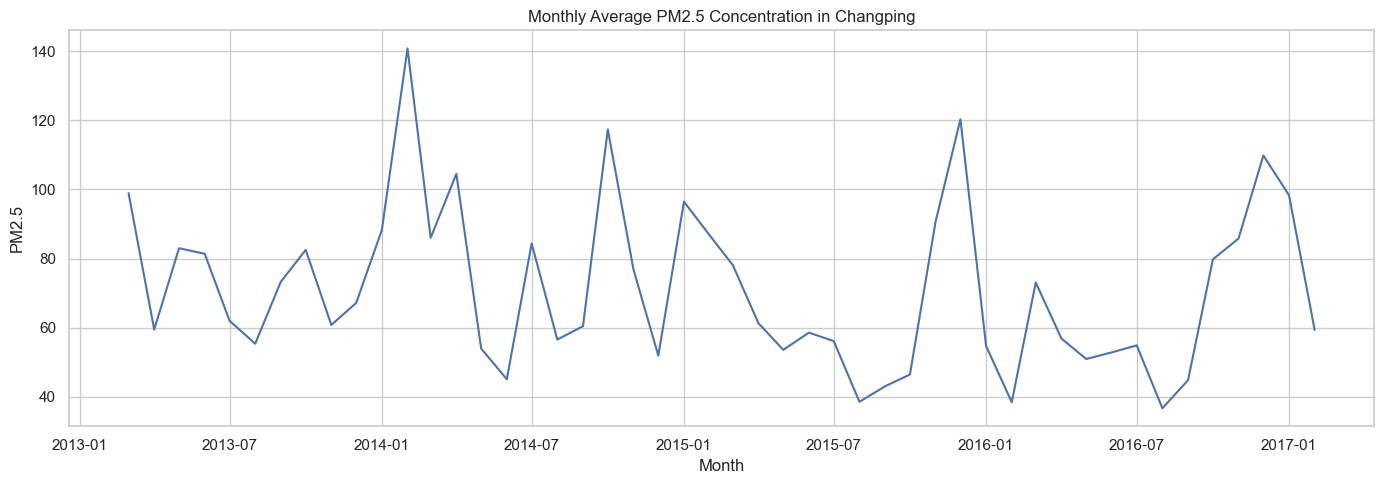

In [8]:
monthly_pm25 = (
    df_clean.set_index("datetime")["PM2.5"]
    .resample("MS")
    .mean()
)

plt.figure(figsize=(14, 5))
plt.plot(monthly_pm25.index, monthly_pm25.values)
plt.title("Monthly Average PM2.5 Concentration in Changping")
plt.xlabel("Month")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

**Insight:** 
- Fluktuasi konsentrasi: Rata-rata PM2.5 menunjukkan fluktuasi yang cukup besar dari bulan ke bulan selama periode pengamatan, sehingga konsentrasi polusi tidak stabil sepanjang waktu.

- Periode dengan konsentrasi tertinggi: Puncak tertinggi terlihat pada Februari 2014, dengan rata-rata PM2.5 sebesar 140,81. Puncak lain terlihat pada Desember 2015, sebesar 120,31, dan Oktober 2014, sebesar 117,34.

- Periode dengan konsentrasi terendah: Rata-rata terendah terlihat pada Agustus 2016, sebesar 36,67, diikuti Februari 2016 sebesar 38,42 dan Agustus 2015 sebesar 38,53.

- Pola temporal: Konsentrasi PM2.5 cenderung menunjukkan variasi berulang, dengan beberapa puncak pada bulan-bulan musim dingin dan nilai yang relatif rendah pada sejumlah bulan musim panas. Pola ini mengindikasikan kemungkinan variasi musiman, tetapi memerlukan analisis lanjutan untuk mengonfirmasinya.

- Kesimpulan: Pemantauan kualitas udara perlu memperhatikan periode dengan konsentrasi PM2.5 tinggi. Namun, grafik ini saja belum cukup untuk menentukan penyebab perubahan konsentrasi atau menyimpulkan tren jangka panjang yang konsisten.

### Pertanyaan 2: Variabel apa yang paling kuat berhubungan dengan PM2.5?

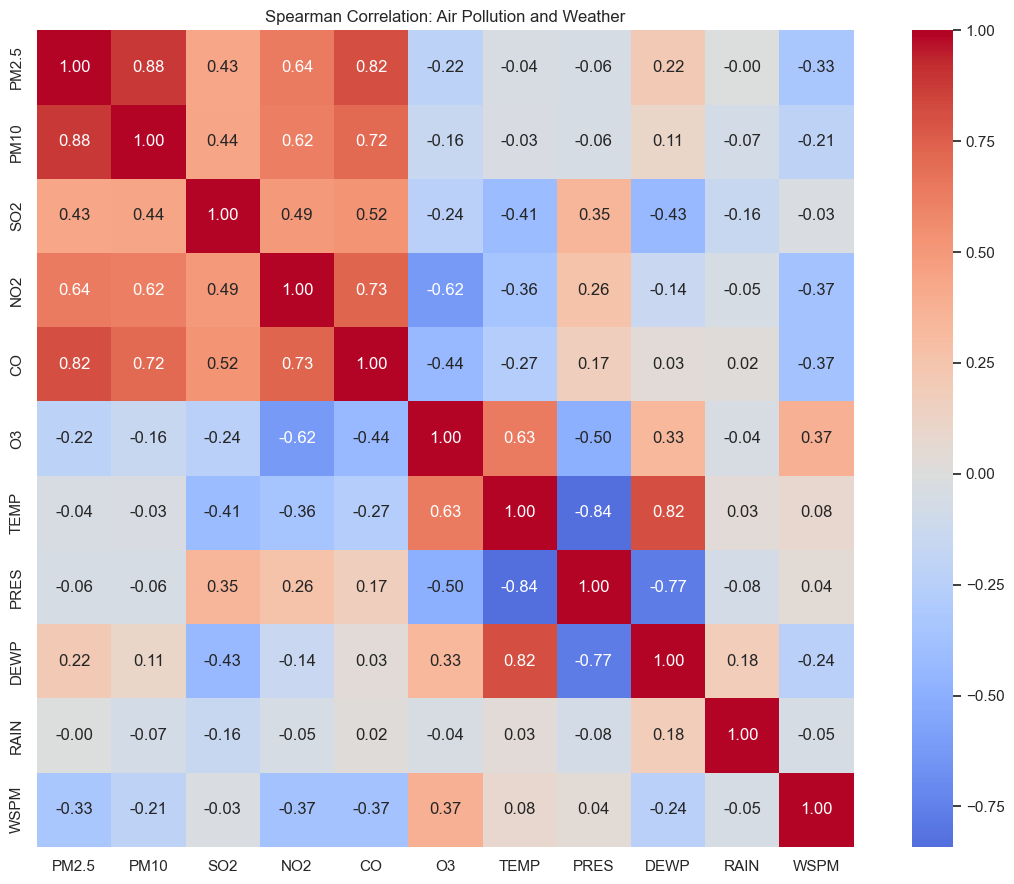

In [9]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Spearman Correlation: Air Pollution and Weather")
plt.tight_layout()
plt.show()

**Insight:** 
- Korelasi positif terkuat dengan PM2.5: PM10 memiliki korelasi Spearman sebesar 0,88, diikuti CO sebesar 0,82 dan NO2 sebesar 0,64. Hal ini menunjukkan bahwa kenaikan nilai ketiga variabel tersebut cenderung berkaitan dengan kenaikan konsentrasi PM2.5.

- Korelasi positif sedang: SO2 memiliki korelasi sebesar 0,43, sedangkan DEWP (dew point temperature) memiliki korelasi sebesar 0,22 terhadap PM2.5.

- Korelasi negatif: WSPM (kecepatan angin) memiliki korelasi negatif sebesar −0,33, sedangkan O3 memiliki korelasi sebesar −0,22. Hubungan ini menunjukkan bahwa nilai PM2.5 cenderung lebih rendah ketika kecepatan angin atau konsentrasi O3 meningkat, meskipun korelasi tidak membuktikan hubungan sebab-akibat.

- Korelasi mendekati nol: TEMP (suhu), PRES (tekanan udara), dan RAIN (curah hujan) memiliki korelasi yang sangat lemah dengan PM2.5 dalam analisis ini.

- Hubungan antarvariabel meteorologi: TEMP dan DEWP memiliki korelasi positif kuat sebesar 0,82, sementara TEMP dan PRES memiliki korelasi negatif kuat sebesar −0,84. Hal ini menunjukkan adanya hubungan yang perlu diperhatikan ketika menganalisis variabel meteorologi secara bersamaan.

- Kesimpulan: PM10, CO, dan NO2 merupakan variabel yang memiliki hubungan monotonik positif paling kuat dengan PM2.5 pada dataset ini. Kecepatan angin juga layak diteliti lebih lanjut sebagai variabel yang berhubungan dengan variasi konsentrasi polusi.

## Analisis Lanjutan (Opsional)

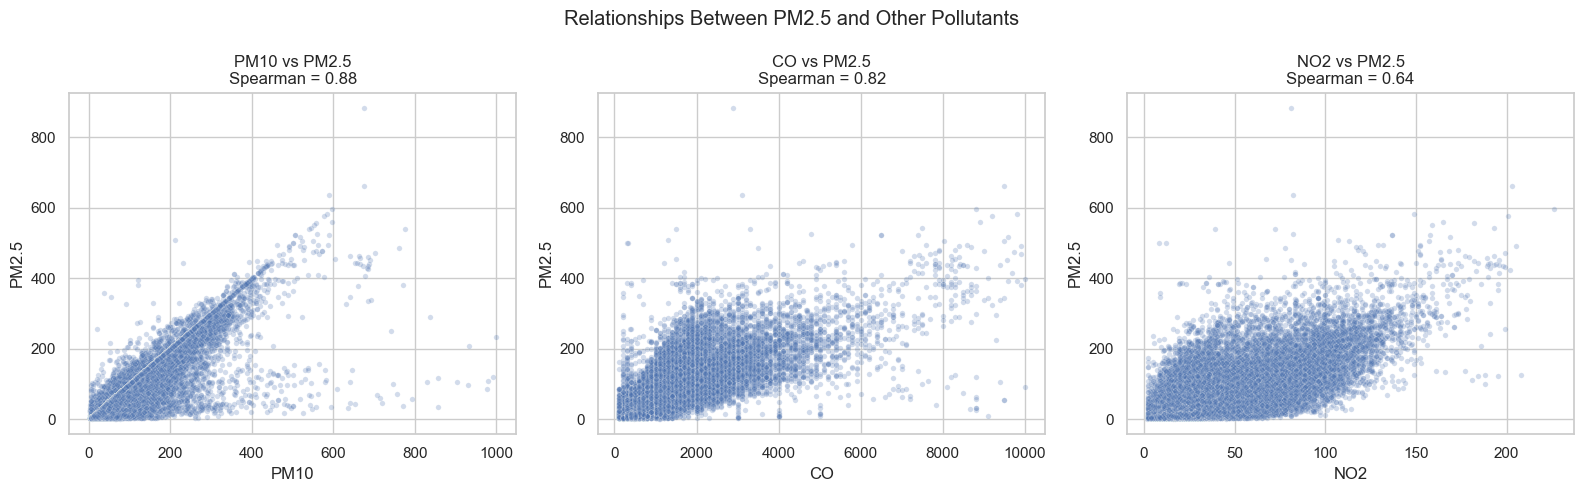

In [10]:
# Analisis lanjutan: hubungan PM2.5 dengan polutan lain

pollutants = ["PM10", "CO", "NO2"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, pollutants):
    data = df_clean[[col, "PM2.5"]].dropna()

    sns.scatterplot(
        data=data,
        x=col,
        y="PM2.5",
        alpha=0.25,
        s=15,
        ax=ax
    )

    corr_value = data[col].corr(
        data["PM2.5"],
        method="spearman"
    )

    ax.set_title(f"{col} vs PM2.5\nSpearman = {corr_value:.2f}")

plt.suptitle("Relationships Between PM2.5 and Other Pollutants")
plt.tight_layout()
plt.show()

**Insight:** 
- PM10 vs PM2.5 (Spearman = 0.88)

Memiliki korelasi positif paling kuat dibandingkan kedua variabel lainnya.

Titik observasi menunjukkan pola peningkatan yang cukup jelas, yaitu semakin tinggi konsentrasi PM10, cenderung semakin tinggi pula konsentrasi PM2.5.

Hal ini mengindikasikan bahwa kedua polutan memiliki pola perubahan konsentrasi yang sangat berkaitan.

- CO vs PM2.5 (Spearman = 0.82)

Menunjukkan hubungan positif yang kuat antara konsentrasi CO dan PM2.5.

Sebagian besar observasi terkonsentrasi pada rentang CO yang relatif rendah hingga menengah, tetapi terdapat beberapa observasi dengan konsentrasi CO sangat tinggi.

Pola ini menunjukkan bahwa peningkatan CO cenderung berkaitan dengan peningkatan PM2.5, meskipun sebaran datanya cukup luas.

- NO2 vs PM2.5 (Spearman = 0.64)

Memiliki hubungan positif dengan kekuatan korelasi yang lebih rendah dibandingkan PM10 dan CO.

Sebagian besar observasi menunjukkan kecenderungan peningkatan PM2.5 seiring meningkatnya konsentrasi NO2.

Namun, penyebaran titik yang lebih luas menunjukkan bahwa hubungan kedua variabel tidak sekuat hubungan PM10 dan PM2.5.

## Conclusion & Recommendation

- Pertanyaan 1: Bagaimana tren konsentrasi PM2.5 di Changping selama periode 2013–2017?

Rata-rata konsentrasi PM2.5 adalah sekitar 71.15 µg/m³, dengan standar deviasi 72.48 µg/m³.

Rata-rata bulanan tertinggi terjadi pada Februari 2014 sebesar 140.81 µg/m³, sedangkan terendah terjadi pada Agustus 2016 sebesar 36.67 µg/m³.

Konsentrasi PM2.5 menunjukkan fluktuasi yang cukup besar sepanjang periode pengamatan. Terdapat indikasi variasi musiman, tetapi diperlukan analisis lebih lanjut untuk memastikan pola tersebut.

- Pertanyaan 2: Variabel apa yang paling kuat berhubungan dengan PM2.5?

PM10 memiliki korelasi positif paling kuat dengan PM2.5 (Spearman = 0.88).

CO menunjukkan korelasi positif sangat kuat (0.82), diikuti NO2 (0.64).

Hasil ini menunjukkan bahwa peningkatan konsentrasi PM10, CO, dan NO2 cenderung berkaitan dengan peningkatan PM2.5.

PM10 menjadi variabel yang paling relevan untuk diprioritaskan dalam analisis hubungan antarpolutan.

**Rekomendasi Action Item:**
1. Meningkatkan pemantauan kualitas udara: Memprioritaskan pemantauan PM2.5 dan PM10 secara berkala, khususnya pada periode dengan konsentrasi polusi tinggi.

2. Melakukan analisis pola musiman: Mengidentifikasi faktor meteorologi dan variasi musiman yang berpotensi memengaruhi peningkatan PM2.5, terutama suhu, kelembapan, dan curah hujan.

3. Mengembangkan sistem peringatan dini: Memanfaatkan data historis PM2.5, PM10, CO, dan NO2 untuk mendukung pengembangan model prediksi kualitas udara.

4. Meningkatkan strategi pengendalian polusi: Melakukan investigasi lebih lanjut terhadap sumber emisi yang berkaitan dengan tingginya konsentrasi partikulat dan gas polutan.

In [11]:
df_clean.to_csv("air_quality_changping_clean.csv", index=False)